# Module 3: Supervised Learning & Baseline Benchmarking

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tulip0648/seismic-fault-impact/blob/main/module3/03_supervised_predictive_modelling.ipynb)

**Course**: BITSF464 Machine Learning — Fall 2026  
**Project**: Seismological Fault Line Discovery & Earthquake Impact Profiling  

---

### Objectives
1. **Two-Stage Benchmarking**: Train and evaluate baseline machine learning algorithms on:
   - **Stage 1 (Base)**: Imputed & standardized physical coordinates and sensor metrics from Module 1.
   - **Stage 2 (Augmented)**: Base features coupled with tectonic fault distances and GMM posterior probabilities from Module 2.
2. **Team Roles**:
   - **Person 1**: Linear & Regularized Models (Logistic Regression with L1/L2/ElasticNet, Ridge/Lasso for MMI).
   - **Person 2**: Probabilistic & Discriminant Models (Gaussian Naive Bayes, LDA with shrinkage, QDA).
   - **Person 3 (You)**: Distance-Based & Margin Models ($k$-Nearest Neighbors, Support Vector Classifiers with probability calibration).
3. **Module 4 Handoff**: Generate cross-validated Out-of-Fold (OOF) prediction probabilities for the stacking meta-learner.


## 0. Environment Setup (Colab & Local)
Detects environment automatically. Sets data and artifact directories without requiring manual path changes.


In [1]:
import os
import sys

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Running in Google Colab.")
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_NAME = "seismic-fault-impact"
    REPO_PATH = f"/content/{REPO_NAME}"
    if not os.path.exists(REPO_PATH):
        !git clone https://github.com/Tulip0648/seismic-fault-impact.git {REPO_PATH}
    %cd {REPO_PATH}/module3
    !pip install -r ../requirements.txt -q
    DATA_BASE_DIR = "../data/processed"
    DATA_AUG_DIR = "../data/augmented"
    ARTIFACTS_DIR = "./artifacts"
    REPORTS_DIR = "./reports"
else:
    print("Running locally.")
    DATA_BASE_DIR = "../data/processed"
    DATA_AUG_DIR = "../data/augmented"
    ARTIFACTS_DIR = "./artifacts"
    REPORTS_DIR = "./reports"

os.makedirs(f"{ARTIFACTS_DIR}/models", exist_ok=True)
os.makedirs(f"{ARTIFACTS_DIR}/oof_predictions", exist_ok=True)
os.makedirs(f"{REPORTS_DIR}/figures", exist_ok=True)
print("Directories initialized successfully.")


Running locally.
Directories initialized successfully.


## 1. Imports & Global Configuration


In [4]:
import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
N_SPLITS = 5

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Global configuration loaded.")


Global configuration loaded.


## 2. Shared Data Ingestion & Target Preparation
Loads the exact same Base and Augmented datasets created by Module 1 and Module 2.  
Target mapping: `green`: 0, `yellow`: 1, `orange`: 2, `red`: 3.


In [5]:
# Target encoding mapping
ALERT_MAP = {'green': 0, 'yellow': 1, 'orange': 2, 'red': 3}
INV_ALERT_MAP = {v: k for k, v in ALERT_MAP.items()}

# 1. Load Base Splits (Module 1)
train_base = pd.read_parquet(os.path.join(DATA_BASE_DIR, "train_base.parquet"))
val_base = pd.read_parquet(os.path.join(DATA_BASE_DIR, "val_base.parquet"))
test_base = pd.read_parquet(os.path.join(DATA_BASE_DIR, "test_base.parquet"))

# 2. Load Augmented Splits (Module 2)
train_aug = pd.read_parquet(os.path.join(DATA_AUG_DIR, "train_augmented.parquet"))
val_aug = pd.read_parquet(os.path.join(DATA_AUG_DIR, "val_augmented.parquet"))
test_aug = pd.read_parquet(os.path.join(DATA_AUG_DIR, "test_augmented.parquet"))

# 3. Ensure target labels are encoded
for df in [train_base, val_base, test_base, train_aug, val_aug, test_aug]:
    if 'alert_label' not in df.columns and 'alert' in df.columns:
        df['alert_label'] = df['alert'].map(ALERT_MAP)

print(f"Train Base shape:      {train_base.shape}")
print(f"Train Augmented shape: {train_aug.shape}")
print(f"Test Base shape:       {test_base.shape}")
print(f"Test Augmented shape:  {test_aug.shape}")


Train Base shape:      (3105, 46)
Train Augmented shape: (3105, 71)
Test Base shape:       (666, 46)
Test Augmented shape:  (666, 71)


## 3. Feature Selection & Cross-Validation Setup
Defines the feature column subsets and initializes the shared 5-Fold Stratified Cross-Validation splitter.


In [6]:
# Excluded columns (metadata, raw categorical strings, and raw targets)
EXCLUDE_COLS = {'event_id', 'time', 'alert', 'alert_label', 'mmi', 'place', 'magType'}

# Base features: columns present in train_base minus excluded
BASE_FEATURES = [c for c in train_base.columns if c not in EXCLUDE_COLS]

# Augmented features: columns present in train_aug minus excluded
AUGMENTED_FEATURES = [c for c in train_aug.columns if c not in EXCLUDE_COLS]

print(f"Base feature count:       {len(BASE_FEATURES)}")
print(f"Augmented feature count:  {len(AUGMENTED_FEATURES)}")

# Shared Stratified K-Fold splitter
cv_splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

def evaluate_predictions(y_true, y_pred, y_prob=None):
    """Calculates Macro F1, Weighted F1, and Multi-Class ROC-AUC (One-vs-Rest)."""
    metrics = {
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'weighted_f1': f1_score(y_true, y_pred, average='weighted'),
    }
    if y_prob is not None:
        try:
            metrics['roc_auc_ovr'] = roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro')
        except Exception:
            metrics['roc_auc_ovr'] = np.nan
    return metrics


Base feature count:       39
Augmented feature count:  64


---
## 4. Person 1: Linear & Regularized Models
**Owner**: Person 1  
**Models**: Logistic Regression (L1, L2, ElasticNet) & Ridge/Lasso for MMI.  
*(Left empty for Person 1 to implement)*


In [ ]:
# --- Person 1: Implement Logistic Regression & Regularized Linear Models here ---


---
## 5. Person 2: Probabilistic & Discriminant Models
**Owner**: Person 2  
**Models**: Gaussian Naive Bayes, Linear Discriminant Analysis (LDA), Quadratic Discriminant Analysis (QDA).  
*(Left empty for Person 2 to implement)*


In [ ]:
# --- Person 2: Implement Naive Bayes, LDA, and QDA here ---


---
## 6. Person 3 (Your Section): Distance-Based & Margin Models

**Owner**: Person 3 (You)  
**Algorithms**:
1. **k-Nearest Neighbors (k-NN)**: Distance-based classification.
2. **Support Vector Classifier (SVC)**: Maximum margin classification with kernel transformations and probability calibration.

---

### 6.1 k-Nearest Neighbors (k-NN) — Stage 1 (Base Features)
Implement and tune $k$-NN on `BASE_FEATURES` using the 5-fold cross-validation split:
- Sweep $k \in [3, 5, 7, 11, 15, 21]$.
- Compare `weights='uniform'` vs `weights='distance'`.
- Compare distance metric (`metric='euclidean'` vs `metric='manhattan'`).


In [ ]:
# DONE (Person 3): Export fitted models (.joblib) and generate OOF prediction vectors
# DONE (Person 3): Implement k-NN on Base Features
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

class CustomKNN(BaseEstimator, ClassifierMixin):
    def __init__(self, k=5, metric='euclidean', weights='uniform'):
        self.k = k
        self.metric = metric
        self.weights = weights

    def fit(self, X, y):
        self.X_train_ = np.asarray(X)
        self.y_train_ = np.asarray(y)
        self.classes_ = np.unique(y)
        return self

    def predict_proba(self, X):
        X = np.asarray(X)
        # performs pairwise distance calculation
        if self.metric == 'euclidean':
            #  The correct formula:
            sq_dists = (
                np.sum(X**2, axis=1, keepdims=True)
                + np.sum(self.X_train_**2, axis=1)
                - 2 * np.dot(X, self.X_train_.T)
            )
            dists = np.sqrt(np.maximum(0.0, sq_dists))
        else:
            dists = np.sum(
                np.abs(X[:, None, :]) - self.X_train_[None, :, :], axis=2
            )
        knn_indices = np.argpartition(dists, self.k, axis=1)[:, :self.k]
        probs = np.zeros((len(X), len(self.classes_)))
        for i, idx in enumerate(knn_indices):
            neighbour_labels = self.y_train_[idx]
            if self.weights == 'distance':
                neighbour_dists = dists[i, idx]
                w = 1/(neighbour_dists+1e-5)
                for label, weight in zip(neighbour_labels, w):
                    probs[i, label] += weight
                total_w = np.sum(w)
                if total_w > 0:
                    probs[i] = probs[i]/total_w
                else:
                    probs[i] = probs[i] = 1.0 / len(self.classes_)
            else:
                counts = np.bincount(neighbour_labels, minlength=len(self.classes_))
                probs[i] = counts/self.k
        return probs
        
    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

X_base = train_base[BASE_FEATURES]
y_base = train_base['alert_label'].values

k_values = [3,5,7,11,15,21]
weights_list = ['uniform', 'distance']
metrics_list = ['euclidean', 'manhattan']

knn_base_results = []

for k in k_values:
    for w in weights_list:
        for m in metrics_list:
            fold_macro_f1s = []
            fold_rocs = []

            for train_idx, val_idx in cv_splitter.split(X_base, y_base):
                X_tr, y_tr = X_base.iloc[train_idx], y_base[train_idx]
                X_va, y_va = X_base.iloc[val_idx], y_base[val_idx]

                pipeline = Pipeline([
                ('scaler', StandardScaler()), 
                ('knn', CustomKNN(k=k, weights=w, metric=m))
                ])
                pipeline.fit(X_tr, y_tr)

                y_pred = pipeline.predict(X_va)
                y_prob = pipeline.predict_proba(X_va)

                scores = evaluate_predictions(y_va, y_pred, y_prob)
                fold_macro_f1s.append(scores['macro_f1'])
                fold_rocs.append(scores['roc_auc_ovr'])
            
            knn_base_results.append(
                {
                    'k': k,
                    'weights': w,
                    'metric': m,
                    'mean_macro_f1': np.mean(fold_macro_f1s),
                    'mean_roc_auc': np.mean(fold_rocs)
                }
            )

df_knn_base = pd.DataFrame(knn_base_results).sort_values(by='mean_macro_f1', ascending=False)
best_knn_base_params = df_knn_base.iloc[0].to_dict()

print("Top 3 k-NN configs on base features:")
print(df_knn_base.head(3))

Top 3 k-NN configs on base features:
    k   weights     metric  mean_macro_f1  mean_roc_auc
6   5  distance  euclidean       0.492542      0.829643
2   3  distance  euclidean       0.492479      0.806615
10  7  distance  euclidean       0.463326      0.851537


### 6.2 k-Nearest Neighbors (k-NN) — Stage 2 (Augmented Features)
Train and evaluate the best $k$-NN configuration on `AUGMENTED_FEATURES` using the identical 5-fold CV splits.


In [ ]:
# DONE (Person 3): Implement k-NN on Augmented Features
X_aug = train_aug[AUGMENTED_FEATURES]
y_aug = train_aug['alert_label'].values

knn_aug_results = []

for k in k_values:
    for w in weights_list:
        for m in metrics_list:
            fold_macro_f1s = []
            fold_rocs = []
            
            for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
                X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
                X_va, y_va = X_aug.iloc[val_idx], y_aug[val_idx]
                
                pipeline = Pipeline([
                    ('scaler', StandardScaler()),
                    ('knn', CustomKNN(k=k, weights=w, metric=m))
                ])
                pipeline.fit(X_tr, y_tr)
                
                y_pred = pipeline.predict(X_va)
                y_prob = pipeline.predict_proba(X_va)
                
                scores = evaluate_predictions(y_va, y_pred, y_prob)
                fold_macro_f1s.append(scores['macro_f1'])
                fold_rocs.append(scores['roc_auc_ovr'])
                
            knn_aug_results.append({
                'k': k,
                'weights': w,
                'metric': m,
                'mean_macro_f1': np.mean(fold_macro_f1s),
                'mean_roc_auc': np.mean(fold_rocs)
            })

df_knn_aug = pd.DataFrame(knn_aug_results).sort_values(by='mean_macro_f1', ascending=False)
best_knn_aug_params = df_knn_aug.iloc[0].to_dict()

print("Top 3 Custom k-NN Configurations on Augmented Features:")
print(df_knn_aug.head(3))

Top 3 Custom k-NN Configurations on Augmented Features:
   k   weights     metric  mean_macro_f1  mean_roc_auc
2  3  distance  euclidean       0.475776      0.778665
6  5  distance  euclidean       0.475002      0.819010
0  3   uniform  euclidean       0.474839      0.778098


### 6.3 Support Vector Classifier (SVC) — Stage 1 (Base Features)
Implement and tune SVC on `BASE_FEATURES`:
- Compare kernels: `kernel='linear'`, `kernel='rbf'`, `kernel='poly'`.
- Tune regularization parameter $C \in [0.1, 1.0, 10.0, 100.0]$ and $\gamma$ (`gamma`).
- Use `class_weight='balanced'` to account for minority classes (Orange & Red).
- Ensure probability calibration is enabled (`probability=True` or `CalibratedClassifierCV`).


In [ ]:
# DONE (Person 3): Implement SVC on Base Features
from sklearn.svm import SVC

# Kernel and hyperparameter candidates
# Note: probability=True enables Platt scaling so probabilities sum to 1.0
svc_param_candidates = [
    {'kernel': 'linear', 'C': 1.0, 'gamma': 'scale'},
    {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'},
    {'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'},
    {'kernel': 'rbf', 'C': 10.0, 'gamma': 'auto'},
    {'kernel': 'poly', 'degree': 2, 'C': 1.0, 'gamma': 'scale'}
]

svc_base_results = []

for params in svc_param_candidates:
    fold_macro_f1s = []
    fold_rocs = []
    
    for train_idx, val_idx in cv_splitter.split(X_base, y_base):
        X_tr, y_tr = X_base.iloc[train_idx], y_base[train_idx]
        X_va, y_va = X_base.iloc[val_idx], y_base[val_idx]
        
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('svc', SVC(
                kernel=params['kernel'],
                C=params['C'],
                gamma=params['gamma'],
                degree=params.get('degree', 3),
                class_weight='balanced',
                probability=True,
                random_state=RANDOM_STATE
            ))
        ])
        pipeline.fit(X_tr, y_tr)
        
        y_pred = pipeline.predict(X_va)
        y_prob = pipeline.predict_proba(X_va)
        
        scores = evaluate_predictions(y_va, y_pred, y_prob)
        fold_macro_f1s.append(scores['macro_f1'])
        fold_rocs.append(scores['roc_auc_ovr'])
        
    svc_base_results.append({
        'config': str(params),
        'kernel': params['kernel'],
        'C': params['C'],
        'gamma': params['gamma'],
        'mean_macro_f1': np.mean(fold_macro_f1s),
        'mean_roc_auc': np.mean(fold_rocs)
    })

df_svc_base = pd.DataFrame(svc_base_results).sort_values(by='mean_macro_f1', ascending=False)
best_svc_base_params = df_svc_base.iloc[0].to_dict()

print("SVC Configurations on Base Features:")
print(df_svc_base)
print("Best Base SVC Parameters:", best_svc_base_params)

SVC Configurations on Base Features:
                                              config  kernel     C  gamma  \
1      {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'}     rbf   1.0  scale   
0   {'kernel': 'linear', 'C': 1.0, 'gamma': 'scale'}  linear   1.0  scale   
2     {'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'}     rbf  10.0  scale   
3      {'kernel': 'rbf', 'C': 10.0, 'gamma': 'auto'}     rbf  10.0   auto   
4  {'kernel': 'poly', 'degree': 2, 'C': 1.0, 'gam...    poly   1.0  scale   

   mean_macro_f1  mean_roc_auc  
1       0.469203      0.960098  
0       0.468630      0.964086  
2       0.468161      0.958918  
3       0.468161      0.958918  
4       0.438985      0.946416  
Best Base SVC Parameters: {'config': "{'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'}", 'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale', 'mean_macro_f1': 0.46920317948501183, 'mean_roc_auc': 0.9600977844055549}


### 6.4 Support Vector Classifier (SVC) — Stage 2 (Augmented Features)
Train and evaluate the best SVC configuration on `AUGMENTED_FEATURES` using the identical 5-fold CV splits.


In [ ]:
# DONE (Person 3): Implement SVC on Augmented Features
svc_aug_results = []

for params in svc_param_candidates:
    fold_macro_f1s = []
    fold_rocs = []
    
    for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
        X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
        X_va, y_va = X_aug.iloc[val_idx], y_aug[val_idx]
        
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('svc', SVC(
                kernel=params['kernel'],
                C=params['C'],
                gamma=params['gamma'],
                degree=params.get('degree', 3),
                class_weight='balanced',
                probability=True,
                random_state=RANDOM_STATE
            ))
        ])
        pipeline.fit(X_tr, y_tr)
        
        y_pred = pipeline.predict(X_va)
        y_prob = pipeline.predict_proba(X_va)
        
        scores = evaluate_predictions(y_va, y_pred, y_prob)
        fold_macro_f1s.append(scores['macro_f1'])
        fold_rocs.append(scores['roc_auc_ovr'])
        
    svc_aug_results.append({
        'config': str(params),
        'kernel': params['kernel'],
        'C': params['C'],
        'gamma': params['gamma'],
        'mean_macro_f1': np.mean(fold_macro_f1s),
        'mean_roc_auc': np.mean(fold_rocs)
    })

df_svc_aug = pd.DataFrame(svc_aug_results).sort_values(by='mean_macro_f1', ascending=False)
best_svc_aug_params = df_svc_aug.iloc[0].to_dict()

print("SVC Configurations on Augmented Features:")
print(df_svc_aug)
print("Best Augmented SVC Parameters:", best_svc_aug_params)

SVC Configurations on Augmented Features:
                                              config  kernel     C  gamma  \
4  {'kernel': 'poly', 'degree': 2, 'C': 1.0, 'gam...    poly   1.0  scale   
3      {'kernel': 'rbf', 'C': 10.0, 'gamma': 'auto'}     rbf  10.0   auto   
2     {'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'}     rbf  10.0  scale   
1      {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'}     rbf   1.0  scale   
0   {'kernel': 'linear', 'C': 1.0, 'gamma': 'scale'}  linear   1.0  scale   

   mean_macro_f1  mean_roc_auc  
4       0.488826      0.949674  
3       0.486158      0.961553  
2       0.486158      0.961553  
1       0.468509      0.960578  
0       0.467034      0.962722  
Best Augmented SVC Parameters: {'config': "{'kernel': 'poly', 'degree': 2, 'C': 1.0, 'gamma': 'scale'}", 'kernel': 'poly', 'C': 1.0, 'gamma': 'scale', 'mean_macro_f1': 0.4888260622373218, 'mean_roc_auc': 0.949674141170785}


### 6.5 Two-Stage Performance Comparison for Person 3 Models
Calculate the improvement gained by adding tectonic fault features:
$$\Delta \text{Macro F1} = \text{Macro F1}_{\text{Augmented}} - \text{Macro F1}_{\text{Base}}$$
$$\Delta \text{ROC-AUC} = \text{ROC-AUC}_{\text{Augmented}} - \text{ROC-AUC}_{\text{Base}}$$


  Model  Base Macro F1  Augmented Macro F1  Δ Macro F1  Base ROC-AUC  \
0  k-NN         0.4925              0.4758     -0.0168        0.8296   
1   SVC         0.4692              0.4888      0.0196        0.9601   

   Augmented ROC-AUC  Δ ROC-AUC  
0             0.7787    -0.0510  
1             0.9497    -0.0104  


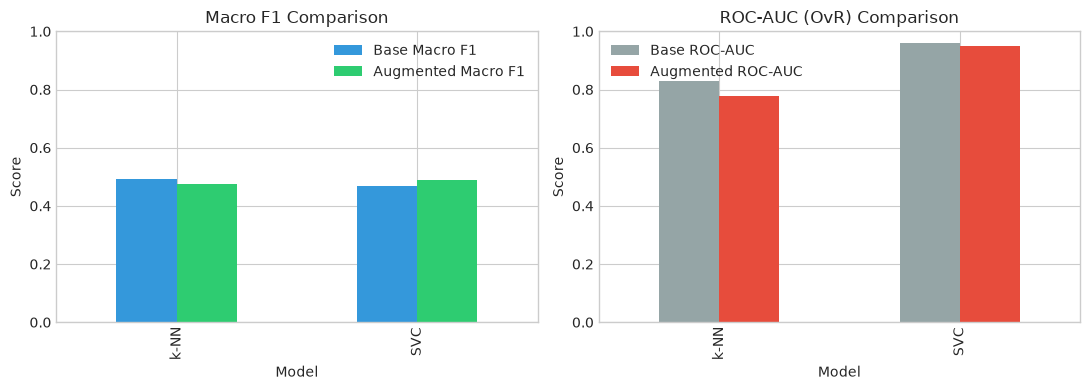

In [20]:
# TODO (Person 3): Compare Base vs Augmented performance (delta table and plot)
# Create comparison dataframe for Person 3's models
comparison_data = [
    {
        'Model': 'k-NN',
        'Base Macro F1': df_knn_base.iloc[0]['mean_macro_f1'],
        'Augmented Macro F1': df_knn_aug.iloc[0]['mean_macro_f1'],
        'Δ Macro F1': df_knn_aug.iloc[0]['mean_macro_f1'] - df_knn_base.iloc[0]['mean_macro_f1'],
        'Base ROC-AUC': df_knn_base.iloc[0]['mean_roc_auc'],
        'Augmented ROC-AUC': df_knn_aug.iloc[0]['mean_roc_auc'],
        'Δ ROC-AUC': df_knn_aug.iloc[0]['mean_roc_auc'] - df_knn_base.iloc[0]['mean_roc_auc'],
    },
    {
        'Model': 'SVC',
        'Base Macro F1': df_svc_base.iloc[0]['mean_macro_f1'],
        'Augmented Macro F1': df_svc_aug.iloc[0]['mean_macro_f1'],
        'Δ Macro F1': df_svc_aug.iloc[0]['mean_macro_f1'] - df_svc_base.iloc[0]['mean_macro_f1'],
        'Base ROC-AUC': df_svc_base.iloc[0]['mean_roc_auc'],
        'Augmented ROC-AUC': df_svc_aug.iloc[0]['mean_roc_auc'],
        'Δ ROC-AUC': df_svc_aug.iloc[0]['mean_roc_auc'] - df_svc_base.iloc[0]['mean_roc_auc'],
    }
]

df_comparison = pd.DataFrame(comparison_data)
#  Simple, clean, and requires zero extra packages:
print(df_comparison.round(4))

# Plot performance delta comparison
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df_comparison.plot(x='Model', y=['Base Macro F1', 'Augmented Macro F1'], kind='bar', ax=axes[0], color=['#3498db', '#2ecc71'])
axes[0].set_title('Macro F1 Comparison')
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel('Score')

df_comparison.plot(x='Model', y=['Base ROC-AUC', 'Augmented ROC-AUC'], kind='bar', ax=axes[1], color=['#95a5a6', '#e74c3c'])
axes[1].set_title('ROC-AUC (OvR) Comparison')
axes[1].set_ylim(0, 1.0)
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.savefig(f"{REPORTS_DIR}/figures/person3_base_vs_augmented.png", dpi=150)
plt.show()

### 6.6 Out-of-Fold (OOF) Prediction Export & Model Serialization
1. Fit the final tuned $k$-NN and SVC models on the full training set and serialize to `artifacts/models/`:
   - `knn_aug.joblib`
   - `svm_rbf_aug.joblib`
2. Save out-of-fold cross-validated probability predictions for both $k$-NN and SVC.


In [22]:
#DONE
# 1. Instantiate best pipelines (CustomKNN + SVC)
best_k = int(best_knn_aug_params['k'])
best_w = best_knn_aug_params['weights']
best_m = best_knn_aug_params['metric']

best_knn_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', CustomKNN(k=best_k, weights=best_w, metric=best_m))
])

best_svc_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(
        kernel=best_svc_aug_params['kernel'],
        C=best_svc_aug_params['C'],
        gamma=best_svc_aug_params['gamma'],
        class_weight='balanced',
        probability=True,
        random_state=RANDOM_STATE
    ))
])

# 2. Out-of-Fold (OOF) cross-validation predictions on the training set
n_classes = len(ALERT_MAP)
oof_knn_train = np.zeros((len(train_aug), n_classes))
oof_svc_train = np.zeros((len(train_aug), n_classes))

for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
    X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
    X_va = X_aug.iloc[val_idx]
    
    best_knn_pipe.fit(X_tr, y_tr)
    oof_knn_train[val_idx] = best_knn_pipe.predict_proba(X_va)
    
    best_svc_pipe.fit(X_tr, y_tr)
    oof_svc_train[val_idx] = best_svc_pipe.predict_proba(X_va)

# 3. Fit on the full training set and predict on the test set
best_knn_pipe.fit(X_aug, y_aug)
best_svc_pipe.fit(X_aug, y_aug)

X_test_aug = test_aug[AUGMENTED_FEATURES]
test_knn_probs = best_knn_pipe.predict_proba(X_test_aug)
test_svc_probs = best_svc_pipe.predict_proba(X_test_aug)

# 4. Serialize models to artifacts/models/
joblib.dump(best_knn_pipe, f"{ARTIFACTS_DIR}/models/knn_aug.joblib")
joblib.dump(best_svc_pipe, f"{ARTIFACTS_DIR}/models/svm_rbf_aug.joblib")
print(f"Serialized models to {ARTIFACTS_DIR}/models/")

# 5. Format OOF prediction columns
oof_p3_train_df = pd.DataFrame({'event_id': train_aug['event_id'], 'true_label': y_aug})
oof_p3_test_df = pd.DataFrame({'event_id': test_aug['event_id'], 'true_label': test_aug['alert_label']})

for c_idx, c_name in INV_ALERT_MAP.items():
    oof_p3_train_df[f'knn_prob_{c_name}'] = oof_knn_train[:, c_idx]
    oof_p3_train_df[f'svm_prob_{c_name}'] = oof_svc_train[:, c_idx]
    oof_p3_test_df[f'knn_prob_{c_name}'] = test_knn_probs[:, c_idx]
    oof_p3_test_df[f'svm_prob_{c_name}'] = test_svc_probs[:, c_idx]

# Save Person 3 OOF artifacts
oof_p3_train_df.to_parquet(f"{ARTIFACTS_DIR}/oof_predictions/oof_train_person3.parquet", index=False)
oof_p3_test_df.to_parquet(f"{ARTIFACTS_DIR}/oof_predictions/oof_test_person3.parquet", index=False)

print(f"Person 3 OOF saved: train shape {oof_p3_train_df.shape}, test shape {oof_p3_test_df.shape}")
print(oof_p3_train_df.head())

Serialized models to ./artifacts/models/
Person 3 OOF saved: train shape (3105, 10), test shape (666, 10)
     event_id  true_label  knn_prob_green  svm_prob_green  knn_prob_yellow  \
0  usc000p27i           1             0.0        0.086593         0.719274   
1  us60008bj6           0             1.0        0.985765         0.000000   
2  us6000le2y           0             1.0        0.996041         0.000000   
3  us6000ldsf           0             1.0        0.989351         0.000000   
4  us7000clbu           0             1.0        0.985253         0.000000   

   svm_prob_yellow  knn_prob_orange  svm_prob_orange  knn_prob_red  \
0         0.739835         0.280726         0.132483           0.0   
1         0.009011         0.000000         0.004108           0.0   
2         0.001308         0.000000         0.002140           0.0   
3         0.006202         0.000000         0.003425           0.0   
4         0.009859         0.000000         0.003530           0.0   

   s

---
## 7. Final Consolidation: Module 4 Stacking Handoff
Combines OOF predictions from Person 1, Person 2, and Person 3 into `oof_train_m3.parquet` and `oof_test_m3.parquet` for Module 4.


In [ ]:
# --- Consolidation Cell: Merges OOF columns from all 3 roles once ready ---
